# Manipulative Language Detection — Dark Patterns Dataset

## Research project
**Task:** Binary classification of online shopping / advertising text into:

- `0` — Neutral
- `1` — Manipulative

## Dataset (new)
The main dataset is now built from two public research datasets:

- **Mathur et al. (2019), "Dark Patterns at Scale"** — manipulative texts collected from ~11K shopping websites, each annotated with a pattern category and type (e.g. *Low-stock Message*, *Countdown Timer*, *Confirmshaming*). GPL-3.0.
- **Yada et al. (2022), "Dark patterns in e-commerce: a dataset and its baseline evaluations"** — the deduplicated Mathur texts plus an equal number of **non-manipulative texts scraped from the same websites**. Apache-2.0.

The combined file `dark_patterns_ecommerce_dataset.csv` is produced by `build_dataset.py`.

Our previous project dataset (`manipulative_language_dataset_300.csv`) is **no longer used for training**. It is kept as an **external test set**: its real advertisements and its synthetic examples (including hard negatives) are used to check how well a model trained on real website text generalizes to our own ads.

## Baseline model
1. **TF-IDF** to convert text into sparse numerical vectors.
2. **Logistic Regression** to classify each text.
3. A held-out **80/20 train/test split**.
4. **5-fold cross-validation**.
5. **External checks** on our original real and synthetic examples.

This is **Experiment 1** of 4. Shared data loading and the train/test split live in `src/data.py`, so every experiment notebook uses exactly the same test set.

In [1]:
# 0. Make the shared `src` package importable (works from the repo root or from notebooks/)

import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

In [2]:
# 1. Imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from src.data import (
    RANDOM_STATE, MAIN_FILE, EXTERNAL_FILE, find_file,
    load_datasets, add_template_groups, split_external, get_split, save_table
)

## 1. Load the datasets

- `dark_patterns_ecommerce_dataset.csv` — main dataset (training + internal evaluation).
- `manipulative_language_dataset_300.csv` — our original project data, used only as an external test set.

Put both files in the `data/` folder (the loader also checks the current folder and `/mnt/data/`).

In [6]:
# 2. Load data

df, external_df = load_datasets()

print("Main dataset:", find_file(MAIN_FILE), df.shape)
print("External dataset:", find_file(EXTERNAL_FILE), external_df.shape)
display(df.head())

Main dataset: C:\Users\bnuri\Desktop\KBTU\manipulative-language-detection\data\dark_patterns_ecommerce_dataset.csv (2349, 11)
External dataset: C:\Users\bnuri\Desktop\KBTU\manipulative-language-detection\data\manipulative_language_dataset_300.csv (427, 13)


,id,text,manipulative,urgency,scarcity,social_proof,emotional_pressure,pattern_category,pattern_type,page_id,source
0,1,FLASH SALE | LIMITED TIME ONLY Shop Now,1,1,0,0,0,Urgency,Limited-time Message,1012,mathur_2019_dark_patterns
1,2,Pillowcases & Shams,0,0,0,0,0,Not Dark Pattern,Not Dark Pattern,158,yada_2022_non_dark_patterns
2,3,Write a review,0,0,0,0,0,Not Dark Pattern,Not Dark Pattern,108,yada_2022_non_dark_patterns
3,4,"To start your return, simply click on the foll...",0,0,0,0,0,Not Dark Pattern,Not Dark Pattern,1425,yada_2022_non_dark_patterns
4,5,newsletter signup (privacy policy),0,0,0,0,0,Not Dark Pattern,Not Dark Pattern,1658,yada_2022_non_dark_patterns


## 2. Basic dataset checks

In [7]:
# 3. Check structure and data quality

print("Columns:")
print(df.columns.tolist())

print("\nMissing values:")
display(df.isna().sum().to_frame("missing"))

print("Duplicate texts:", df["text"].duplicated().sum())

print("\nSource distribution:")
display(df["source"].value_counts(dropna=False).to_frame("count"))

print("\nTarget distribution:")
display(df["manipulative"].value_counts().sort_index().rename(
    index={0: "Neutral", 1: "Manipulative"}
).to_frame("count"))

print("\nDark pattern types (manipulative texts only):")
display(df.loc[df["manipulative"] == 1, "pattern_type"].value_counts().to_frame("count"))

print("\nText length (words) by class:")
display(df.assign(n_words=df["text"].str.split().str.len())
          .groupby("manipulative")["n_words"].describe())

Columns:
['id', 'text', 'manipulative', 'urgency', 'scarcity', 'social_proof', 'emotional_pressure', 'pattern_category', 'pattern_type', 'page_id', 'source']

Missing values:


,missing
id,0
text,0
manipulative,0
urgency,0
scarcity,0
social_proof,0
emotional_pressure,0
pattern_category,0
pattern_type,0
page_id,0


Duplicate texts: 0

Source distribution:


,count
source,
mathur_2019_dark_patterns,1178
yada_2022_non_dark_patterns,1171



Target distribution:


,count
manipulative,
Neutral,1171
Manipulative,1178



Dark pattern types (manipulative texts only):


,count
pattern_type,
Low-stock Message,395
Activity Notification,311
Confirmshaming,129
Countdown Timer,129
Limited-time Message,81
Pressured Selling,45
Hard to Cancel,27
High-demand Message,23
Visual Interference,12



Text length (words) by class:


,count,mean,std,min,25%,50%,75%,max
manipulative,,,,,,,,
0,1171.0,5.764304,8.852879,1.0,2.0,3.0,6.0,116.0
1,1178.0,9.109508,12.892038,1.0,4.0,6.0,9.0,143.0


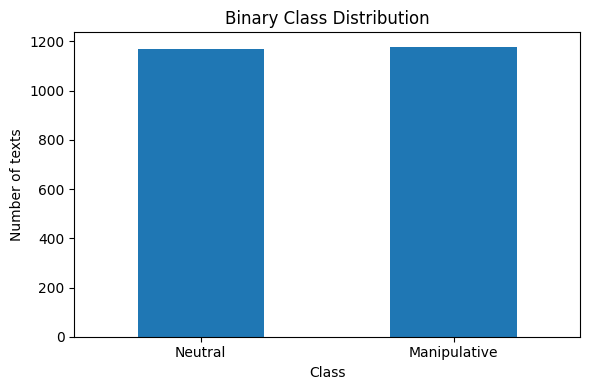

In [8]:
# 4. Visualize the binary class distribution

class_counts = (
    df["manipulative"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Neutral", 1: "Manipulative"})
)

plt.figure(figsize=(6, 4))
class_counts.plot(kind="bar")
plt.title("Binary Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of texts")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 3. Main data, near-duplicate groups, and external test sets

Many dark-pattern texts are generated from the same website template and differ only in a number
(e.g. *"Only 2 left in stock"* vs. *"Only 3 left in stock"*).
If such near-duplicates end up on both sides of a train/test split, the test score is inflated.

To prevent this, every text gets a **template group** (lower-cased, all digits replaced by `#`).
All splits and cross-validation folds below are **group-aware**: texts from the same template never appear in both training and test data.

The original project data is split into two external test sets:
- **real** — real advertising examples (mostly from Kazakhstan),
- **synthetic** — our generated examples, including hard negatives.

In [9]:
# 5. Main data, template groups, external sets (see src/data.py)

main_df, groups = add_template_groups(df)

print("Main examples:", len(main_df))
print("Unique templates (groups):", len(np.unique(groups)))
print("Texts that share a template with another text:",
      int(main_df["template"].duplicated(keep=False).sum()))

real_df, external_synthetic_df = split_external(external_df)

print("\nExternal real examples:", len(real_df))
print("External synthetic examples:", len(external_synthetic_df))

print("\nMain class distribution:")
display(main_df["manipulative"].value_counts().sort_index().to_frame("count"))

print("\nExample near-duplicate group:")
biggest = main_df["template"].value_counts().index[0]
display(main_df.loc[main_df["template"] == biggest, ["text", "pattern_type"]].head(5))

Main examples: 2349
Unique templates (groups): 2092
Texts that share a template with another text: 348

External real examples: 57
External synthetic examples: 370

Main class distribution:


,count
manipulative,
0,1171
1,1178



Example near-duplicate group:


,text,pattern_type
13,ONLY 8 LEFT,Low-stock Message
67,ONLY 3 LEFT,Low-stock Message
90,Only 1 Left,Low-stock Message
92,Only 33 left,Low-stock Message
172,Only 26 Left,Low-stock Message


## 4. Train/test split

We use an **80/20 split** with `StratifiedGroupKFold` (first fold):

- **stratified** — the proportion of Neutral and Manipulative texts is preserved,
- **grouped** — near-duplicate templates never appear in both training and test data.

The split is defined once in `src/data.py` (`get_split`) and reused by the multi-label, embedding, and neural-network notebooks, so all models are compared on exactly the same test set.

In [10]:
# 6. Train/test split (stratified + grouped, see src/data.py)

X = main_df["text"]
y = main_df["manipulative"]

train_idx, test_idx = get_split(main_df, groups)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Training examples:", len(X_train))
print("Test examples:", len(X_test))
print("Shared templates between train and test:",
      len(set(groups[train_idx]) & set(groups[test_idx])))

print("\nTraining target distribution:")
display(y_train.value_counts().sort_index().to_frame("count"))

print("\nTest target distribution:")
display(y_test.value_counts().sort_index().to_frame("count"))

Training examples: 1881
Test examples: 468
Shared templates between train and test: 0

Training target distribution:


,count
manipulative,
0,920
1,961



Test target distribution:


,count
manipulative,
0,251
1,217


## 5. Build the baseline model

### TF-IDF
TF-IDF represents each text as a sparse vector based on word importance.

We use:

- unigrams: `"offer"`
- bigrams: `"limited offer"`

### Logistic Regression
Logistic Regression predicts:

\[
P(\text{Manipulative} \mid \text{text})
\]

The default classification threshold is `0.5`.

In [11]:
# 7. TF-IDF + Logistic Regression pipeline

baseline_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2)
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    )
])

baseline_model

,steps,"[('tfidf', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None


In [12]:
# 8. Train the model

baseline_model.fit(X_train, y_train)

print("Baseline model trained.")

Baseline model trained.


## 6. Evaluate on the held-out test set

In [13]:
# 9. Predictions

y_pred = baseline_model.predict(X_test)
y_prob = baseline_model.predict_proba(X_test)[:, 1]

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Value": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ]
})

display(metrics.style.format({"Value": "{:.3f}"}))

,Metric,Value
0,Accuracy,0.949
1,Precision,0.966
2,Recall,0.922
3,F1-score,0.943


In [14]:
# 10. Detailed classification report

print(classification_report(
    y_test,
    y_pred,
    target_names=["Neutral", "Manipulative"],
    digits=3,
    zero_division=0
))

              precision    recall  f1-score   support

     Neutral      0.935     0.972     0.953       251
Manipulative      0.966     0.922     0.943       217

    accuracy                          0.949       468
   macro avg      0.951     0.947     0.948       468
weighted avg      0.949     0.949     0.949       468



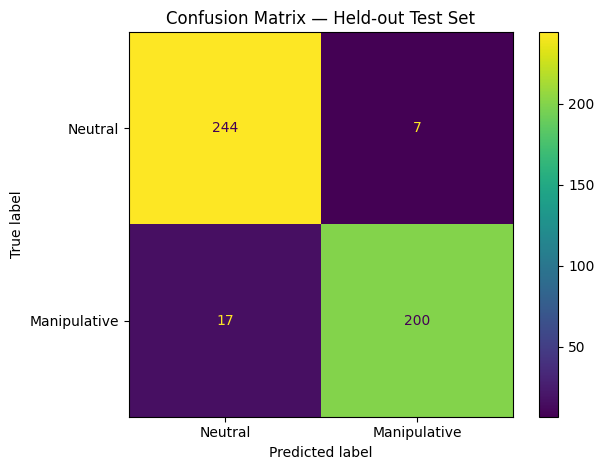

In [15]:
# 11. Confusion matrix

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Neutral", "Manipulative"],
    values_format="d"
)
plt.title("Confusion Matrix — Held-out Test Set")
plt.tight_layout()
plt.show()

### How to read the confusion matrix

- **True Neutral → Predicted Neutral:** correct neutral predictions.
- **True Manipulative → Predicted Manipulative:** correct manipulative predictions.
- **True Neutral → Predicted Manipulative:** false positives.
- **True Manipulative → Predicted Neutral:** false negatives.

## 7. Error analysis

In [16]:
# 12. Inspect mistakes

test_results = pd.DataFrame({
    "text": X_test,
    "true_label": y_test,
    "predicted_label": y_pred,
    "manipulative_probability": y_prob
})

test_results["correct"] = (
    test_results["true_label"] == test_results["predicted_label"]
)

errors = (
    test_results[~test_results["correct"]]
    .sort_values("manipulative_probability")
)

print("Number of errors:", len(errors))
display(errors)

Number of errors: 24


,text,true_label,predicted_label,manipulative_probability,correct
1721,Professional Color Tool Kit / Addons,1,0,0.223208,False
278,Shipping Insurance Remove Insurance,1,0,0.242508,False
380,0011Days:0088Hours:4411Minutes:21125445Seconds,1,0,0.268187,False
140,I'll Shop Without A Discount,1,0,0.275647,False
1047,MOST POPULAR,1,0,0.321097,False
1536,0:44:56,1,0,0.350325,False
1339,With 1-year Care Subscription 10 days history,1,0,0.383400,False
1115,Let's make sure you have everything else you need,1,0,0.386409,False
1267,No USB or Y-Adapter!? Our USB Sound Card is hi...,1,0,0.391498,False
1041,HIGH DEMAND,1,0,0.403371,False


## 8. 5-fold cross-validation

A single train/test split can depend on which examples happened to enter the test set.

To get a more stable estimate, we also use **5-fold stratified group cross-validation** (`StratifiedGroupKFold`), so near-duplicate templates stay within one fold.

In [17]:
# 13. Cross-validation

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = cross_validate(
    baseline_model,
    X,
    y,
    groups=groups,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1"]
)

cv_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Mean": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean()
    ],
    "Std": [
        cv_results["test_accuracy"].std(),
        cv_results["test_precision"].std(),
        cv_results["test_recall"].std(),
        cv_results["test_f1"].std()
    ]
})

display(
    cv_summary.style.format({
        "Mean": "{:.3f}",
        "Std": "{:.3f}"
    })
)

,Metric,Mean,Std
0,Accuracy,0.945,0.009
1,Precision,0.965,0.015
2,Recall,0.922,0.019
3,F1-score,0.943,0.013


## 9. External check — our real advertisements

Now we retrain the same baseline on the **full main dataset**.

Then we test it on the real advertising examples from our original project data.

This is a **cross-dataset** test: the model was trained on English text from US/international shopping websites, while our real examples are advertisements (many from Kazakhstan) written in a different style.
The set is small, so this is a sanity check rather than a final benchmark.

In [18]:
# 14. Fit on the full main dataset

final_baseline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2)
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    )
])

final_baseline.fit(
    main_df["text"],
    main_df["manipulative"]
)

print("Model retrained on the full main dataset.")

Model retrained on the full main dataset.


In [19]:
# 15. Evaluate on real examples

if len(real_df) > 0:
    real_pred = final_baseline.predict(real_df["text"])
    real_prob = final_baseline.predict_proba(real_df["text"])[:, 1]

    real_results = real_df[
        ["id", "text", "manipulative", "source"]
    ].copy()

    real_results = real_results.rename(
        columns={"manipulative": "true_label"}
    )

    real_results["predicted_label"] = real_pred
    real_results["manipulative_probability"] = real_prob
    real_results["correct"] = (
        real_results["true_label"] == real_results["predicted_label"]
    )

    print("Real-set accuracy:",
          round(accuracy_score(real_results["true_label"],
                               real_results["predicted_label"]), 3))

    print("Real-set F1:",
          round(f1_score(real_results["true_label"],
                         real_results["predicted_label"],
                         zero_division=0), 3))

    display(
        real_results.sort_values(
            "manipulative_probability",
            ascending=False
        )
    )
else:
    print("No real examples were found.")

Real-set accuracy: 0.561
Real-set F1: 0.468


,id,text,true_label,source,predicted_label,manipulative_probability,correct
381,382,Only 3 apartments remain in this new residenti...,1,real_estate_ad,1,0.935324,True
300,301,Only 3 left — order now!,1,online store,1,0.926164,True
397,398,Only four hotel rooms remain at this weekend r...,1,hotel_ad,1,0.894841,True
377,378,Only 5 smartphones left at this price — order ...,1,ecommerce_ad,1,0.853974,True
388,389,Almost sold out — only a few tickets remain fo...,1,event_ad,1,0.833454,True
378,379,"Get up to KZT 50,000 cashback today — the prom...",1,bank_promotion,1,0.769004,True
416,417,The limited sample contained data from 45 resp...,0,hard_negative,1,0.738146,False
387,388,Only today: 20% off food delivery orders above...,1,food_delivery_ad,1,0.709021,True
303,304,Don't miss out on up to KZT 3000000 free ad cr...,1,online advertisement,1,0.700610,True
412,413,Only two employees participated in the initial...,0,hard_negative,1,0.692914,False


## 9b. External check — our synthetic examples

Our original synthetic set contains manipulative ad copy, neutral ad-style texts, and **hard negatives** — neutral sentences that reuse manipulative-sounding words (*"The sale period ends on Friday as listed in the published schedule"*).
This tests whether the model learned the manipulative intent or just keywords such as *ends*, *only*, or *left*.

In [20]:
# 15b. Evaluate on our synthetic examples, broken down by subtype

ext_pred = final_baseline.predict(external_synthetic_df["text"])
ext_results = external_synthetic_df[["text", "manipulative", "source"]].copy()
ext_results["predicted_label"] = ext_pred
ext_results["correct"] = ext_results["manipulative"] == ext_results["predicted_label"]

print("External synthetic accuracy:", round(accuracy_score(ext_results["manipulative"], ext_pred), 3))
print("External synthetic F1:", round(f1_score(ext_results["manipulative"], ext_pred, zero_division=0), 3))

print("\nAccuracy by subtype:")
display(ext_results.groupby("source")["correct"].agg(["mean", "count"])
        .rename(columns={"mean": "accuracy"}).style.format({"accuracy": "{:.3f}"}))

print("\nExamples of errors:")
display(ext_results[~ext_results["correct"]].head(15))

External synthetic accuracy: 0.578
External synthetic F1: 0.414

Accuracy by subtype:


,accuracy,count
source,,
synthetic_ad_copy,0.297,185
synthetic_hard_negative,0.822,90
synthetic_neutral_ad_style,0.895,95



Examples of errors:


,text,manipulative,source,predicted_label,correct
4,Registration ends on October 15 according to t...,0,synthetic_hard_negative,1,False
7,The sale period ends on Friday as listed in th...,0,synthetic_hard_negative,1,False
10,Ignoring small leaks can lead to expensive wat...,1,synthetic_ad_copy,0,False
16,Give your parents the care they truly deserve.,1,synthetic_ad_copy,0,False
17,Do not wait until tomorrow to start saving.,1,synthetic_ad_copy,0,False
19,The ultimate upgrade for a truly flawless expe...,1,synthetic_ad_copy,0,False
20,Professionals warn that ignored maintenance ca...,1,synthetic_ad_copy,0,False
21,Experts recommend protecting the people you lo...,1,synthetic_ad_copy,0,False
24,Just five places remain for the ultimate learn...,1,synthetic_ad_copy,0,False
25,Avoid devastating data loss with the most powe...,1,synthetic_ad_copy,0,False


## 10. Inspect what the TF-IDF model learned

Logistic Regression assigns a coefficient to every TF-IDF feature.

- Large **positive** coefficients push the prediction toward `Manipulative`.
- Large **negative** coefficients push the prediction toward `Neutral`.

This is useful for checking whether the model learned meaningful linguistic patterns or only superficial dataset artifacts.

In [21]:
# 16. Most influential TF-IDF features

tfidf = final_baseline.named_steps["tfidf"]
classifier = final_baseline.named_steps["classifier"]

feature_names = np.array(tfidf.get_feature_names_out())
coefficients = classifier.coef_[0]

top_n = 20

top_manipulative_idx = np.argsort(coefficients)[-top_n:][::-1]
top_neutral_idx = np.argsort(coefficients)[:top_n]

top_manipulative = pd.DataFrame({
    "feature": feature_names[top_manipulative_idx],
    "coefficient": coefficients[top_manipulative_idx]
})

top_neutral = pd.DataFrame({
    "feature": feature_names[top_neutral_idx],
    "coefficient": coefficients[top_neutral_idx]
})

print("Features most associated with MANIPULATIVE:")
display(top_manipulative)

print("Features most associated with NEUTRAL:")
display(top_neutral)

Features most associated with MANIPULATIVE:


,feature,coefficient
0,left,5.205071
1,in,4.445599
2,only,4.180836
3,bought,3.438916
4,purchased,3.390436
5,limited,3.308003
6,no,3.082813
7,this,2.781697
8,people,2.768981
9,time,2.468038


Features most associated with NEUTRAL:


,feature,coefficient
0,all,-1.485235
1,remotes,-1.231010
2,shop,-1.103824
3,view,-1.101068
4,and,-1.006415
5,new,-0.926908
6,cookies,-0.923983
7,accessories,-0.870928
8,of,-0.829360
9,hair,-0.756167


In [22]:
# 17. Save results for the comparison in Experiments 3 and 4

save_table(metrics, "exp1_test_metrics")
save_table(cv_summary, "exp1_cv_summary")
print("Saved to results/.")

Saved to results/.


## 11. Baseline experiment summary

### Current experiment
- **Task:** Binary Manipulative vs Neutral classification
- **Representation:** TF-IDF
- **Classifier:** Logistic Regression
- **Main training data:** Mathur et al. (2019) dark patterns + Yada et al. (2022) non-dark-pattern texts from the same websites
- **Internal evaluation:** Group-aware held-out test set + 5-fold group cross-validation
- **External evaluation:** Our original real and synthetic advertising examples

### Next research steps
1. Build the **multi-label technique classifier**.
2. Compare TF-IDF with **Word2Vec / dense embeddings**.
3. Later compare with **contextual embeddings**.
4. Perform systematic error analysis on the external sets.

# Experiment 1 — Interpretation and Limitations

### Interpretation
- The internal test set measures how well the model separates manipulative and neutral texts collected from the same shopping websites.
- Group-aware splitting prevents near-duplicate templates from inflating this score.
- The external sets show whether this transfers to our own advertisements.

### Limitations
1. **Length and form shortcut.** Neutral texts in the main dataset are often very short UI fragments (product names, menu items), while manipulative texts are full phrases. Part of the internal score can come from this difference rather than from manipulative language itself.
2. **Domain shift.** The main dataset is website UI text (stock counters, timers, pop-ups), not advertising copy. The external results show how much this matters.
3. Binary classification does not identify the specific technique.
4. TF-IDF relies on lexical patterns and does not model deeper context.